<a href="https://colab.research.google.com/github/saketh-varma06/DL_ASSIGNMENTS/blob/main/DL_ASS_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PyTorch version: 2.11.0+cu130
Device: cuda



README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 87599
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 10570
    })
})
Dataset downloaded successfully.

Preprocessing dataset...
Training examples: 5000
Validation examples: 500
Testing examples: 500
Vocabulary size: 13497

Training BiLSTM Baseline (No Attention)...
Epoch 1/5 | Train Loss: 4.5707 | Validation Loss: 4.2029
Epoch 2/5 | Train Loss: 4.0420 | Validation Loss: 4.0244
Epoch 3/5 | Train Loss: 3.7247 | Validation Loss: 4.0007
Epoch 4/5 | Train Loss: 3.4803 | Validation Loss: 4.0183
Epoch 5/5 | Train Loss: 3.2714 | Validation Loss: 4.0297

Training BiLSTM with Cross-Attention...
Epoch 1/5 | Train Loss: 4.5916 | Validation Loss: 4.2519
Epoch 2/5 | Train Loss: 4.0798 | Validation Loss: 4.0554
Epoch 3/5 | Train Loss: 3.7564 | Validation Loss: 3.9622
Epoch 4/5 | Train Loss: 3.4926 | Validatio

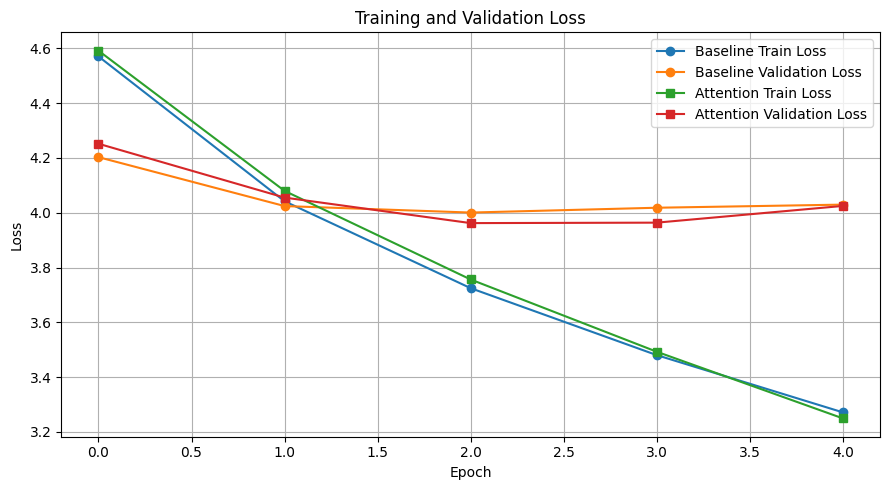


MODEL COMPARISON
                   Model  Exact Match  Token F1
         BiLSTM Baseline        0.032    0.0737
BiLSTM + Cross-Attention        0.044    0.0817


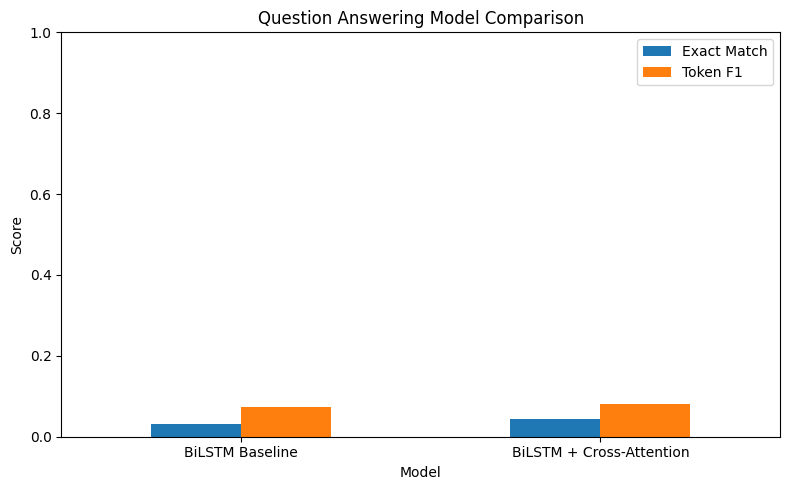


SAMPLE QUESTION ANSWERING PREDICTIONS

Question: Which NFL team represented the AFC at Super Bowl 50?
Actual answer: Denver Broncos
Baseline prediction: roman numerals
Attention prediction: super

Question: Which NFL team represented the NFC at Super Bowl 50?
Actual answer: Carolina Panthers
Baseline prediction: roman numerals
Attention prediction: super

Question: Where did Super Bowl 50 take place?
Actual answer: Santa Clara, California
Baseline prediction: roman numerals
Attention prediction: super

Question: Which NFL team won Super Bowl 50?
Actual answer: Denver Broncos
Baseline prediction: roman numerals
Attention prediction: super

Question: What color was used to emphasize the 50th anniversary of the Super Bowl?
Actual answer: gold
Baseline prediction: roman numerals
Attention prediction: super

OBSERVATIONS
1. SQuAD contains context passages, questions, and answer spans.
2. The baseline conditions its prediction on a pooled question vector.
3. Cross-attention lets each contex

In [ ]:
# ================================================================
# LAB / EXP 15: ATTENTION MECHANISMS IN PYTORCH
# Task: Extractive Question Answering
# Dataset: SQuAD 1.1 (public Hugging Face dataset)
# Models: BiLSTM Baseline vs BiLSTM + Attention
# ================================================================

!pip -q install datasets scikit-learn pandas matplotlib

import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from collections import Counter
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score

# ================================================================
# 1. SETUP
# ================================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)

# Hyperparameters
MAX_TRAIN = 5000
MAX_VAL = 500
MAX_TEST = 500
MAX_CONTEXT_LEN = 180
MAX_QUESTION_LEN = 32
MAX_VOCAB = 30000
EMBED_DIM = 100
HIDDEN_DIM = 64
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 0.001

# ================================================================
# 2. DOWNLOAD SQUAD DATASET
# ================================================================

print("\nDownloading SQuAD 1.1 dataset...")

squad = load_dataset("rajpurkar/squad")

print(squad)
print("Dataset downloaded successfully.")

# ================================================================
# 3. TOKENIZATION WITH CHARACTER OFFSETS
# ================================================================

def tokenize_with_offsets(text):
    # Word and punctuation tokens, with original character positions.
    return [
        (match.group().lower(), match.start(), match.end())
        for match in re.finditer(r"\w+|[^\w\s]", text)
    ]

def get_raw_examples(split, limit):
    examples = []
    source = squad[split]

    for row in source:
        context = row["context"]
        question = row["question"]
        answers = row["answers"]

        if not answers["text"]:
            continue

        answer_text = answers["text"][0]
        answer_start_char = answers["answer_start"][0]
        answer_end_char = answer_start_char + len(answer_text)

        context_tokens = tokenize_with_offsets(context)
        question_tokens = [
            token for token, _, _ in tokenize_with_offsets(question)
        ]

        if not context_tokens or not question_tokens:
            continue

        # Locate answer's start and end token.
        start_idx = None
        end_idx = None

        for i, (_, start_char, end_char) in enumerate(context_tokens):
            if start_char <= answer_start_char < end_char:
                start_idx = i

            if start_char < answer_end_char <= end_char:
                end_idx = i

        if start_idx is None or end_idx is None:
            continue

        if start_idx > end_idx:
            continue

        # Skip answers that fall outside the truncated context.
        if end_idx >= MAX_CONTEXT_LEN:
            continue

        examples.append({
            "context": [t[0] for t in context_tokens[:MAX_CONTEXT_LEN]],
            "question": question_tokens[:MAX_QUESTION_LEN],
            "start": start_idx,
            "end": end_idx,
            "original_context": context,
            "original_question": question,
            "answer": answer_text
        })

        if len(examples) >= limit:
            break

    return examples

print("\nPreprocessing dataset...")

train_examples = get_raw_examples("train", MAX_TRAIN)
val_examples = get_raw_examples("validation", MAX_VAL)
test_examples = get_raw_examples("validation", MAX_TEST)

if not train_examples or not val_examples or not test_examples:
    raise ValueError(
        "No usable examples were created. Check the dataset download "
        "and tokenization settings."
    )

print("Training examples:", len(train_examples))
print("Validation examples:", len(val_examples))
print("Testing examples:", len(test_examples))

# ================================================================
# 4. BUILD VOCABULARY FROM TRAINING DATA ONLY
# ================================================================

PAD_IDX = 0
UNK_IDX = 1

counter = Counter()

for example in train_examples:
    counter.update(example["context"])
    counter.update(example["question"])

vocab = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}

for word, _ in counter.most_common(MAX_VOCAB - 2):
    if word not in vocab:
        vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

def numericalize(tokens, max_len):
    ids = [vocab.get(token, UNK_IDX) for token in tokens[:max_len]]
    length = len(ids)
    ids += [PAD_IDX] * (max_len - len(ids))
    return ids, length

# ================================================================
# 5. CREATE PYTORCH DATASET
# ================================================================

class QADataset(Dataset):
    def __init__(self, examples):
        self.examples = examples

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        ex = self.examples[idx]

        context_ids, context_len = numericalize(
            ex["context"], MAX_CONTEXT_LEN
        )
        question_ids, question_len = numericalize(
            ex["question"], MAX_QUESTION_LEN
        )

        return {
            "context": torch.tensor(context_ids, dtype=torch.long),
            "question": torch.tensor(question_ids, dtype=torch.long),
            "context_len": torch.tensor(context_len, dtype=torch.long),
            "question_len": torch.tensor(question_len, dtype=torch.long),
            "start": torch.tensor(ex["start"], dtype=torch.long),
            "end": torch.tensor(ex["end"], dtype=torch.long)
        }

train_ds = QADataset(train_examples)
val_ds = QADataset(val_examples)
test_ds = QADataset(test_examples)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False
)

# ================================================================
# 6. BASELINE MODEL WITHOUT ATTENTION
# ================================================================

class QABaseline(nn.Module):
    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(
            len(vocab), EMBED_DIM, padding_idx=PAD_IDX
        )

        self.context_encoder = nn.LSTM(
            EMBED_DIM, HIDDEN_DIM,
            batch_first=True, bidirectional=True
        )

        self.question_encoder = nn.LSTM(
            EMBED_DIM, HIDDEN_DIM,
            batch_first=True, bidirectional=True
        )

        # Context representation + pooled question representation.
        self.start_head = nn.Linear(HIDDEN_DIM * 4, 1)
        self.end_head = nn.Linear(HIDDEN_DIM * 4, 1)

        self.dropout = nn.Dropout(0.2)

    def forward(self, context, question):
        context_emb = self.embedding(context)
        question_emb = self.embedding(question)

        context_out, _ = self.context_encoder(context_emb)
        question_out, _ = self.question_encoder(question_emb)

        question_mask = (question != PAD_IDX).unsqueeze(-1)
        question_sum = (question_out * question_mask).sum(dim=1)
        question_count = question_mask.sum(dim=1).clamp(min=1)

        question_vector = question_sum / question_count

        question_repeated = question_vector.unsqueeze(1).expand(
            -1, context.size(1), -1
        )

        combined = torch.cat(
            [context_out, question_repeated], dim=-1
        )
        combined = self.dropout(combined)

        start_logits = self.start_head(combined).squeeze(-1)
        end_logits = self.end_head(combined).squeeze(-1)

        context_mask = context == PAD_IDX
        start_logits = start_logits.masked_fill(context_mask, -1e9)
        end_logits = end_logits.masked_fill(context_mask, -1e9)

        return start_logits, end_logits

# ================================================================
# 7. ATTENTION-BASED MODEL
# ================================================================

class QAAttention(nn.Module):
    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(
            len(vocab), EMBED_DIM, padding_idx=PAD_IDX
        )

        self.context_encoder = nn.LSTM(
            EMBED_DIM, HIDDEN_DIM,
            batch_first=True, bidirectional=True
        )

        self.question_encoder = nn.LSTM(
            EMBED_DIM, HIDDEN_DIM,
            batch_first=True, bidirectional=True
        )

        # Dot-product cross-attention:
        # each context token attends to question tokens.
        self.scale = (HIDDEN_DIM * 2) ** 0.5

        self.start_head = nn.Linear(HIDDEN_DIM * 4, 1)
        self.end_head = nn.Linear(HIDDEN_DIM * 4, 1)

        self.dropout = nn.Dropout(0.2)

    def forward(self, context, question):
        context_emb = self.embedding(context)
        question_emb = self.embedding(question)

        context_out, _ = self.context_encoder(context_emb)
        question_out, _ = self.question_encoder(question_emb)

        # Attention scores: [batch, context_len, question_len]
        scores = torch.bmm(
            context_out, question_out.transpose(1, 2)
        ) / self.scale

        # Ignore padding tokens in the question.
        question_mask = question == PAD_IDX
        scores = scores.masked_fill(
            question_mask.unsqueeze(1), -1e9
        )

        attention_weights = torch.softmax(scores, dim=-1)

        # Context-specific question representation.
        attended_question = torch.bmm(
            attention_weights, question_out
        )

        combined = torch.cat(
            [context_out, attended_question], dim=-1
        )
        combined = self.dropout(combined)

        start_logits = self.start_head(combined).squeeze(-1)
        end_logits = self.end_head(combined).squeeze(-1)

        # Ignore padded context positions.
        context_mask = context == PAD_IDX
        start_logits = start_logits.masked_fill(context_mask, -1e9)
        end_logits = end_logits.masked_fill(context_mask, -1e9)

        return start_logits, end_logits

# ================================================================
# 8. TRAINING AND EVALUATION FUNCTIONS
# ================================================================

def evaluate_loss(model, loader, criterion):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for batch in loader:
            context = batch["context"].to(device)
            question = batch["question"].to(device)
            start = batch["start"].to(device)
            end = batch["end"].to(device)

            start_logits, end_logits = model(context, question)

            loss = (
                criterion(start_logits, start)
                + criterion(end_logits, end)
            ) / 2

            total_loss += loss.item() * context.size(0)

    return total_loss / len(loader.dataset)

def train_model(model, name):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_state = None

    print(f"\nTraining {name}...")

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0

        for batch in train_loader:
            context = batch["context"].to(device)
            question = batch["question"].to(device)
            start = batch["start"].to(device)
            end = batch["end"].to(device)

            optimizer.zero_grad()

            start_logits, end_logits = model(context, question)

            start_loss = criterion(start_logits, start)
            end_loss = criterion(end_logits, end)
            loss = (start_loss + end_loss) / 2

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * context.size(0)

        train_loss = total_loss / len(train_loader.dataset)
        val_loss = evaluate_loss(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Validation Loss: {val_loss:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history

# ================================================================
# 9. TRAIN BOTH MODELS
# ================================================================

baseline_model, baseline_history = train_model(
    QABaseline(), "BiLSTM Baseline (No Attention)"
)

attention_model, attention_history = train_model(
    QAAttention(), "BiLSTM with Cross-Attention"
)

# ================================================================
# 10. PREDICTIONS AND QA METRICS
# ================================================================

def predict_span(model, context_ids, question_ids):
    model.eval()

    context = torch.tensor([context_ids], dtype=torch.long).to(device)
    question = torch.tensor([question_ids], dtype=torch.long).to(device)

    with torch.no_grad():
        start_logits, end_logits = model(context, question)

    start = int(start_logits.argmax(dim=1).item())
    end = int(end_logits.argmax(dim=1).item())

    # Ensure the predicted span is valid and bounded.
    if end < start:
        end = start

    end = min(end, MAX_CONTEXT_LEN - 1)

    return start, end

def span_metrics(model, examples):
    exact_matches = []
    f1_scores = []

    for ex in examples:
        context_ids, _ = numericalize(
            ex["context"], MAX_CONTEXT_LEN
        )
        question_ids, _ = numericalize(
            ex["question"], MAX_QUESTION_LEN
        )

        pred_start, pred_end = predict_span(
            model, context_ids, question_ids
        )

        true_start, true_end = ex["start"], ex["end"]

        exact_matches.append(
            int(pred_start == true_start and pred_end == true_end)
        )

        predicted_tokens = set(
            range(pred_start, pred_end + 1)
        )
        true_tokens = set(
            range(true_start, true_end + 1)
        )

        overlap = len(predicted_tokens & true_tokens)

        precision = overlap / len(predicted_tokens)
        recall = overlap / len(true_tokens)

        if precision + recall == 0:
            f1 = 0.0
        else:
            f1 = (
                2 * precision * recall / (precision + recall)
            )

        f1_scores.append(f1)

    return {
        "Exact Match": float(np.mean(exact_matches)),
        "Token F1": float(np.mean(f1_scores))
    }

baseline_metrics = span_metrics(baseline_model, test_examples)
attention_metrics = span_metrics(attention_model, test_examples)

print("\nBASELINE TEST METRICS")
print(baseline_metrics)

print("\nATTENTION MODEL TEST METRICS")
print(attention_metrics)

# ================================================================
# 11. LOSS CURVES
# ================================================================

plt.figure(figsize=(9, 5))

plt.plot(
    baseline_history["train_loss"],
    marker="o",
    label="Baseline Train Loss"
)
plt.plot(
    baseline_history["val_loss"],
    marker="o",
    label="Baseline Validation Loss"
)
plt.plot(
    attention_history["train_loss"],
    marker="s",
    label="Attention Train Loss"
)
plt.plot(
    attention_history["val_loss"],
    marker="s",
    label="Attention Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ================================================================
# 12. MODEL COMPARISON
# ================================================================

comparison = pd.DataFrame([
    {
        "Model": "BiLSTM Baseline",
        **baseline_metrics
    },
    {
        "Model": "BiLSTM + Cross-Attention",
        **attention_metrics
    }
])

print("\nMODEL COMPARISON")
print(comparison.round(4).to_string(index=False))

comparison.set_index("Model").plot(
    kind="bar", figsize=(8, 5), ylim=(0, 1)
)
plt.title("Question Answering Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ================================================================
# 13. DISPLAY SAMPLE PREDICTIONS
# ================================================================

def decode_answer(example, model):
    context_ids, _ = numericalize(
        example["context"], MAX_CONTEXT_LEN
    )
    question_ids, _ = numericalize(
        example["question"], MAX_QUESTION_LEN
    )

    start, end = predict_span(model, context_ids, question_ids)

    answer_tokens = example["context"][start:end + 1]
    return " ".join(answer_tokens)

print("\nSAMPLE QUESTION ANSWERING PREDICTIONS")

for i in range(min(5, len(test_examples))):
    ex = test_examples[i]

    baseline_answer = decode_answer(ex, baseline_model)
    attention_answer = decode_answer(ex, attention_model)

    print("\nQuestion:", ex["original_question"])
    print("Actual answer:", ex["answer"])
    print("Baseline prediction:", baseline_answer)
    print("Attention prediction:", attention_answer)

# ================================================================
# 14. OBSERVATIONS AND CONCLUSION
# ================================================================

print("\nOBSERVATIONS")
print("1. SQuAD contains context passages, questions, and answer spans.")
print("2. The baseline conditions its prediction on a pooled question vector.")
print("3. Cross-attention lets each context token use question information.")
print("4. Exact Match measures exact answer-span agreement.")
print("5. Token F1 measures overlap between predicted and true answer spans.")
print("6. Results depend on vocabulary size, sample size, and training time.")

best_model_name = (
    "BiLSTM + Cross-Attention"
    if attention_metrics["Token F1"] > baseline_metrics["Token F1"]
    else "BiLSTM Baseline"
)

print("\nCONCLUSION")
print("Best model by test Token F1:", best_model_name)
print(
    "This experiment compares an attention mechanism with a question-"
    "conditioned baseline for extractive question answering."
)